# K-Nearest Neighbors: From-Scratch Implementation and Experimental Study

## Project Objective

The objective of this project is to understand the K-Nearest Neighbors (KNN) algorithm beyond simply using a machine learning library.

The project focuses on:

- Understanding how KNN performs classification using distance and nearest neighbors.
- Studying the effect of feature scaling on KNN performance.
- Investigating how different values of K affect model behavior.
- Comparing Euclidean and Manhattan distance metrics.
- Implementing KNN from scratch using Python and NumPy.
- Validating the custom implementation against scikit-learn.
- Studying how irrelevant/noisy features affect KNN performance.

The broader aim is to develop practical machine learning implementation and experimental-analysis skills.



## Problem Statement

This project uses the Breast Cancer Wisconsin dataset to classify tumors as:

- **B** — Benign
- **M** — Malignant

Rather than focusing only on achieving high classification accuracy, the project investigates how different design choices affect KNN and whether a manually implemented KNN can reproduce the behavior of scikit-learn's implementation.



## Dataset Description

This project uses the Breast Cancer Wisconsin dataset for binary classification.

Each row represents one tumor sample, and the dataset contains:

- **569 samples**
- **30 numerical input features**
- **2 target classes**
  - **B** — Benign
  - **M** — Malignant

The input features describe characteristics of cell nuclei, including measurements related to:

- Radius
- Texture
- Perimeter
- Area
- Smoothness
- Compactness
- Concavity
- Concave points
- Symmetry
- Fractal dimension

For many measurements, the dataset contains three forms:

- Mean
- Standard error
- Worst/largest value

The target variable is `diagnosis`, which is separated from the input features before model training.

In [ ]:
data.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
data.shape

(569, 31)

In [ ]:
data["diagnosis"].value_counts()

,count
diagnosis,
B,357
M,212


### Class Distribution Observation

The dataset is not perfectly balanced. The benign class contains more samples than the malignant class.

Because of this imbalance, model performance should not be evaluated using accuracy alone. Precision, recall, F1-score, and the confusion matrix are also considered during evaluation.

## Research Questions and Hypotheses

This project is structured around a series of controlled experiments to understand how KNN behaves under different conditions.

### Research Question 1
How does feature scaling affect KNN classification performance?

**Hypothesis:**  
Because KNN relies on distance calculations, features with larger numerical ranges may dominate the distance metric. Standardization is expected to improve performance by allowing features to contribute on a more comparable scale.

---

### Research Question 2
How does the value of K affect KNN performance?

**Hypothesis:**  
Very small values of K may be more sensitive to noise and local variations, while very large values may oversmooth the decision boundary. A moderate value of K is expected to provide better generalization.

---

### Research Question 3
Does the choice of distance metric affect KNN performance?

**Hypothesis:**  
Euclidean and Manhattan distance may produce different neighborhood structures and therefore may lead to different classification results.

---

### Research Question 4
Can a KNN classifier implemented from scratch reproduce the predictions of scikit-learn's KNN implementation?

**Hypothesis:**  
If the distance calculation, neighbor selection, and majority voting logic are implemented correctly, the custom KNN should closely match the scikit-learn implementation under the same experimental conditions.

---

### Research Question 5
How do irrelevant or noisy features affect KNN performance?

**Hypothesis:**  
Because KNN calculates distance across all input dimensions, adding irrelevant features may distort neighborhood relationships and reduce classification performance.

## Data Preparation and Experimental Setup

Before training the KNN models, the dataset was prepared so that all experiments could be compared fairly.

### Feature and Target Separation

The target column `diagnosis` was separated from the numerical input features.

- `X` contains the input features.
- `y` contains the target labels (`B` and `M`).

### Train-Test Split

The dataset was split into:

- **80% training data**
- **20% testing data**

A fixed `random_state=42` was used for reproducibility.

Because the target classes are not perfectly balanced, stratified splitting was used so that the train and test sets preserve approximately the same class proportions.

### Feature Scaling

KNN is a distance-based algorithm, so feature scaling is important.

For experiments involving scaled data:

- `StandardScaler` was fitted only on the training data.
- The same fitted scaler was then used to transform the test data.

This prevents information from the test set from leaking into the training process.

### Evaluation Metrics

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

Special attention was given to the malignant class (`M`) because accuracy alone can hide poor minority-class performance.

In [ ]:
                                 #SEE THE CODE BELOW

# [Experimental Dataset ](https://www.kaggle.com/datasets/yasserh/breast-cancer-dataset/data)

**Importing essential Libraries for experimentation**

In [ ]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Load the Dataset

In [ ]:
data=pd.read_csv("data\breast_cancer.csv")
data.head(5)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


# Basic Understanding of dataset

**What are the features?**

In [ ]:
print("Dataset features (columns):")
features=data.copy()
features=features.drop(columns=['id','diagnosis','Unnamed: 32'],axis=1)
print(features.columns)

Dataset features (columns):
Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')


**What are the classes?**

In [ ]:
classes=data['diagnosis']
classes.unique()

array(['M', 'B'], dtype=object)

**Are there missing values?**

In [ ]:
data.isna().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


**How many samples belong to each class?**

In [ ]:
data['diagnosis'].value_counts()



,count
diagnosis,
B,357
M,212


# EDA

In [ ]:

data.drop(columns=['id'],inplace=True,axis=1)
data.head(5)



,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
data.drop(columns=['Unnamed: 32'],inplace=True,axis=1)
data.head(5)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# train and test



In [ ]:
x=data.drop(columns=['diagnosis'],axis=1)
y=data['diagnosis']


x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
x_train.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,...,19.19,33.88,123.80,1150.0,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452
170,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,...,13.50,15.64,86.97,549.1,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771
407,12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,...,14.40,27.01,91.63,645.8,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151
430,14.90,22.53,102.10,685.0,0.09947,0.22250,0.27330,0.09711,0.2041,0.06898,...,16.35,27.57,125.40,832.7,0.14190,0.7090,0.9019,0.24750,0.2866,0.11550
27,18.61,20.25,122.10,1094.0,0.09440,0.10660,0.14900,0.07731,0.1697,0.05699,...,21.31,27.26,139.90,1403.0,0.13380,0.2117,0.3446,0.14900,0.2341,0.07421


In [ ]:
y_train.head(5)

,diagnosis
10,M
170,B
407,B
430,M
27,M


In [ ]:
x_test.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
120,11.41,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,...,12.82,15.97,83.74,510.5,0.1548,0.2390,0.21020,0.08958,0.3016,0.08523
250,20.94,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,...,25.58,27.00,165.30,2010.0,0.1211,0.3172,0.69910,0.21050,0.3126,0.07849
375,16.17,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,...,16.97,19.14,113.10,861.5,0.1235,0.2550,0.21140,0.12510,0.3153,0.08960
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,16.33,30.86,109.50,826.4,0.1431,0.3026,0.31940,0.15650,0.2718,0.09353
455,13.38,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,...,15.05,41.61,96.69,705.6,0.1172,0.1421,0.07003,0.07763,0.2196,0.07675


In [ ]:
y_test.head(5)

,diagnosis
120,B
250,M
375,B
99,M
455,B


# Investigate Features

In [ ]:
x.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


**Observation**:
The dataset contains features with substantially different numerical ranges. For example, area_worst ranges from approximately 185 to 4254, whereas fractal_dimension_worst ranges from approximately 0.055 to 0.208. Since KNN relies on distance calculations, features with larger numerical magnitudes may dominate the distance metric even if they are not necessarily more important for classification.

**Hypothesis**:
Standardizing the features before applying KNN may improve classification performance because it allows features to contribute on a more comparable numerical scale.

# Experiment 0 — Baseline KNN Without Feature Scaling

In [ ]:
model=KNeighborsClassifier(n_neighbors=5)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

**check Baseline result of unscaled data**

In [ ]:
y_accuracy=accuracy_score(y_test,y_pred)
y_accuracy

0.9122807017543859

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           B       0.89      0.99      0.93        72
           M       0.97      0.79      0.87        42

    accuracy                           0.91       114
   macro avg       0.93      0.89      0.90       114
weighted avg       0.92      0.91      0.91       114



### Baseline Result

Accuracy: 91.22

### Observation

The unscaled KNN baseline achieved an overall accuracy of 91%. However, class-wise performance is uneven. The model achieved very high recall for benign cases (0.99) but lower recall for malignant cases (0.79). This indicates that the model is more reliable at identifying benign samples than malignant samples.

### Interpretation

Since the dataset is moderately imbalanced and KNN is sensitive to distance calculations, the poorer recall for the malignant class may be influenced by both class distribution and unscaled feature magnitudes. Therefore, accuracy alone is insufficient for evaluating this model, and malignant-class recall and F1-score should be monitored in later experiments.


In [ ]:
confusion_matrix(y_test, y_pred)

array([[71,  1],
       [ 9, 33]])

#Experiment 1 - KNN after Feature Scaling

In [ ]:
scale = StandardScaler()

x_train_scaled = scale.fit_transform(x_train)
x_test_scaled = scale.transform(x_test)



In [ ]:
model.fit(x_train_scaled, y_train)
y_pred_scaled = model.predict(x_test_scaled)

In [ ]:
print(classification_report(y_test, y_pred_scaled))

              precision    recall  f1-score   support

           B       0.95      0.99      0.97        72
           M       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



**Observation**:

After standardizing the features, KNN accuracy improved from 91% to 96%. More importantly, recall for the malignant class improved from 0.79 to 0.90, while precision remained high at 0.97.


**Interpretation**:

This supports the hypothesis that feature scaling improves KNN performance on this dataset. Since KNN relies on distance calculations, standardization prevents features with larger numerical ranges from dominating the distance metric. The improvement in malignant-class recall suggests that scaling also helped the model identify more malignant samples correctly.

In [ ]:
confusion_matrix(y_test,y_pred_scaled)

array([[71,  1],
       [ 4, 38]])

#Experiment 2 - Using different K value

In [ ]:
k=0
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for k in range(1, 20):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train_scaled, y_train)

    y_pred = model.predict(x_test_scaled)

    results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_M": precision_score(y_test, y_pred, pos_label="M"),
        "Recall_M": recall_score(y_test, y_pred, pos_label="M"),
        "F1_M": f1_score(y_test, y_pred, pos_label="M")
    })

results_df = pd.DataFrame(results)
print(results_df)



     K  Accuracy  Precision_M  Recall_M      F1_M
0    1  0.929825     0.925000  0.880952  0.902439
1    2  0.912281     0.970588  0.785714  0.868421
2    3  0.938596     0.972973  0.857143  0.911392
3    4  0.938596     1.000000  0.833333  0.909091
4    5  0.956140     0.974359  0.904762  0.938272
5    6  0.947368     0.973684  0.880952  0.925000
6    7  0.956140     0.974359  0.904762  0.938272
7    8  0.947368     0.973684  0.880952  0.925000
8    9  0.947368     0.973684  0.880952  0.925000
9   10  0.947368     0.973684  0.880952  0.925000
10  11  0.947368     0.973684  0.880952  0.925000
11  12  0.947368     0.973684  0.880952  0.925000
12  13  0.947368     0.973684  0.880952  0.925000
13  14  0.938596     0.972973  0.857143  0.911392
14  15  0.947368     0.973684  0.880952  0.925000
15  16  0.938596     0.972973  0.857143  0.911392
16  17  0.938596     0.972973  0.857143  0.911392
17  18  0.938596     0.972973  0.857143  0.911392
18  19  0.938596     0.972973  0.857143  0.911392


**Observation:**

Performance varies noticeably for smaller values of \(K\), especially in malignant-class recall. \(K=5\) and \(K=7\) achieved the highest accuracy of 95.61% and also the strongest malignant-class F1-score of 0.94. Both values produced only 4 false negatives for the malignant class.


**Interpretation:**

Very small values of \(K\) are more sensitive to local noise and individual samples. As \(K\) increases, the decision boundary becomes more stable. However, after a moderate range, performance begins to plateau or slightly decrease, suggesting that very large \(K\) values may oversmooth local structure. In this experiment, \(K=5\) and \(K=7\) provided the best balance between sensitivity and generalization.

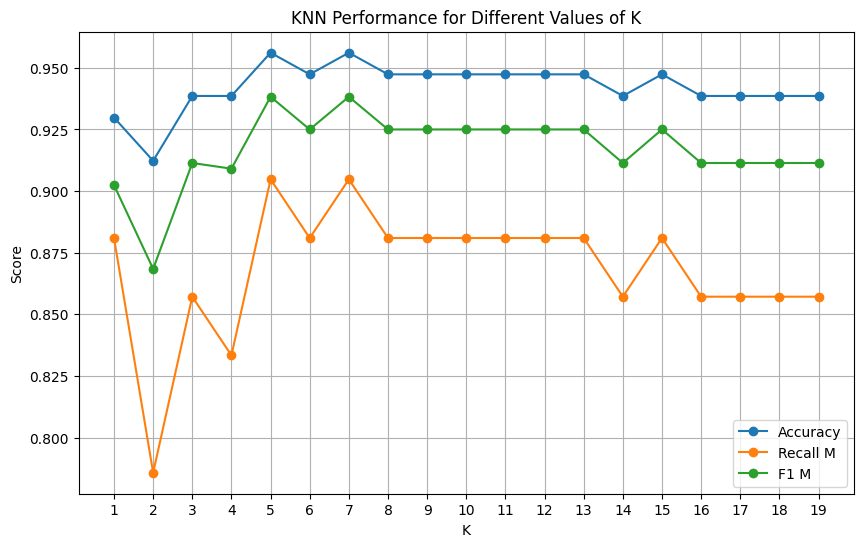

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(results_df["K"], results_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(results_df["K"], results_df["Recall_M"], marker="o", label="Recall M")
plt.plot(results_df["K"], results_df["F1_M"], marker="o", label="F1 M")

plt.xlabel("K")
plt.ylabel("Score")
plt.title("KNN Performance for Different Values of K")

plt.xticks(results_df["K"])
plt.grid(True)
plt.legend()

plt.show()

# Experiment 3 — Effect of Distance Metric

## Research Question
Does the choice of distance metric affect KNN performance?

## Hypothesis
Euclidean and Manhattan distance may produce different neighbourhoods,
which may affect classification performance even when K is fixed.

##Euclidean Metric

In [ ]:
e_model=KNeighborsClassifier(n_neighbors=5,metric='euclidean')
e_model.fit(x_train_scaled,y_train)
y_pred_e=e_model.predict(x_test_scaled)

##Manhattan Metric

In [ ]:
m_model = KNeighborsClassifier(n_neighbors=5, metric='manhattan')
m_model.fit(x_train_scaled, y_train)
y_pred_m = m_model.predict(x_test_scaled)

## Euclidean vs Manhattan

In [ ]:
e_precision= precision_score(y_test, y_pred_e, pos_label="M")
e_recall= recall_score(y_test, y_pred_e, pos_label="M")
e_f1= f1_score(y_test, y_pred_e, pos_label="M")

In [ ]:
m_precision= precision_score(y_test, y_pred_m, pos_label="M")
m_recall= recall_score(y_test, y_pred_m, pos_label="M")
m_f1= f1_score(y_test, y_pred_m, pos_label="M")

In [ ]:
pd.DataFrame({
    "Metric": ["Euclidean", "Manhattan"],
    "Accuracy": [accuracy_score(y_test, y_pred_e), accuracy_score(y_test, y_pred_m)],
    "Precision_M": [e_precision, m_precision],
    "Recall_M": [e_recall, m_recall],
    "F1_M": [e_f1, m_f1]
})

,Metric,Accuracy,Precision_M,Recall_M,F1_M
0,Euclidean,0.95614,0.974359,0.904762,0.938272
1,Manhattan,0.95614,0.974359,0.904762,0.938272


**Observation**:

Euclidean and Manhattan distance produced identical classification performance for \(K=5\) on the standardized dataset. Both achieved 95.61% accuracy, 0.90 recall for the malignant class, and 0.94 malignant-class F1-score.

**Interpretation**:

Under the current dataset, preprocessing, train-test split, and \(K=5\), changing the distance metric from Euclidean to Manhattan did not alter the final predictions enough to affect the evaluated metrics. This suggests that both metrics produce similarly useful neighbourhood structures in this experimental setup.

**Limitation**:

This result should not be generalized to all datasets or all values of \(K\). Different feature distributions, dimensionalities, or datasets may produce different behavior.

#KNN From Scratch

In [ ]:
from collections import Counter
class myKNN:
    def __init__(self, k):
      self.k = k

    def fit(self, X, y):
      self.X_train = np.array(X)
      self.y_train = np.array(y)
    def euclidean_distance(self, x1, x2):
      return np.sqrt(np.sum((x1 - x2)**2))

    def predict(self, new_points):
      predictions=[self.predict_class(new_point) for new_point in new_points]
      return np.array(predictions)
    def predict_class(self, new_point):
      distances = [self.euclidean_distance(point, new_point ) for point in self.X_train]
      k_indices=np.argsort(distances)[:self.k]
      k_nearest_labels=[self.y_train[i] for i in k_indices]
      most_common=Counter(k_nearest_labels).most_common(1)
      return most_common[0][0]


##Testing my KNN

In [ ]:
myKNN_model=myKNN(k=5)
myKNN_model.fit(x_train_scaled,y_train)
y_pred_myknn=myKNN_model.predict(x_test_scaled)

accuracy_myknn=accuracy_score(y_test,y_pred_myknn)
print(accuracy_myknn)

0.956140350877193


In [ ]:
agreement = np.mean(y_pred_myknn == y_pred_e)
print("Agreement:", agreement)

Agreement: 1.0


In [ ]:
print(classification_report(y_test, y_pred_myknn))

              precision    recall  f1-score   support

           B       0.95      0.99      0.97        72
           M       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
print(confusion_matrix(y_test, y_pred_myknn))

[[71  1]
 [ 4 38]]


##Validation of From-Scratch Implementation
The custom KNN implementation achieved an accuracy of 95.61%, matching the scikit-learn implementation under the same preprocessing, train-test split, \(K=5\), and Euclidean distance. Prediction agreement between the two implementations was 100%. This provides evidence that the fundamental KNN logic implemented from scratch is functioning correctly.

#Experiment 4 — Effect of irrelevant/noisy features on KNN

##Preparation of first 2 noisy columns

In [ ]:
x_noise_1 = x.copy()
x_noise_1["noise_1"] = [np.random.normal(0, 1) for _ in range(len(x))]
x_noise_1["noise_2"] = [np.random.normal(0, 1) for _ in range(len(x))]




In [ ]:
x_noise_1.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,noise_1,noise_2
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,-0.404069,0.932829
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0.688347,-0.695645
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0.665106,-0.940936
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1.100800,0.532116
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,-1.259296,1.215874


##Testing the same noisy Dataset

In [ ]:


x_noisy1_train,x_noisy1_test,y_noisy1_train,y_noisy1_test=train_test_split(x_noise_1,y,test_size=0.2,random_state=42,stratify=y)

scalar=StandardScaler()
x_noisy1_train=scalar.fit_transform(x_noisy1_train)
x_noisy1_test=scalar.transform(x_noisy1_test)

noisy_model=KNeighborsClassifier(n_neighbors=5)
noisy_model.fit(x_noisy1_train,y_noisy1_train)
y_pred_noisy=noisy_model.predict(x_noisy1_test)

print(accuracy_score(y_noisy1_test,y_pred_noisy))
print(classification_report(y_noisy1_test,y_pred_noisy))
print(confusion_matrix(y_noisy1_test,y_pred_noisy))




0.956140350877193
              precision    recall  f1-score   support

           B       0.95      0.99      0.97        72
           M       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

[[71  1]
 [ 4 38]]


In [ ]:
accuracy_noisy2=accuracy_score(y_noisy1_test,y_pred_noisy)
recall_noisy2=recall_score(y_noisy1_test,y_pred_noisy,pos_label='M')
f1_noisy2=f1_score(y_noisy1_test,y_pred_noisy,pos_label='M')


**observation**:

model accuracy has dropped to 94.72% on adding 2 noisy columns

 x0= 30 features
 x1= 30 features + 2 noisy columns

 **later on...**

 x2 =  features + 5 noisy columns

 and so on upto 30 noisy columns

In [ ]:
model=KNeighborsClassifier()

In [ ]:
print(type(model))

<class 'sklearn.neighbors._classification.KNeighborsClassifier'>


##adding more noisy columns

In [ ]:
x_noise_2=x_noise_1.copy()


np.random.seed(42)



x_noise_2["noise_3"] = np.random.normal(size=len(x))
x_noise_2["noise_4"] = np.random.normal(size=len(x))
x_noise_2["noise_5"] = np.random.normal(size=len(x))




In [ ]:
x_noise_2.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,noise_1,noise_2,noise_3,noise_4,noise_5
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,0.6656,0.7119,0.2654,0.4601,0.11890,-0.404069,0.932829,0.496714,-0.351513,0.597400
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,0.1866,0.2416,0.1860,0.2750,0.08902,0.688347,-0.695645,-0.138264,0.018418,0.701173
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,0.4245,0.4504,0.2430,0.3613,0.08758,0.665106,-0.940936,0.647689,1.676437,-0.297564
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,0.8663,0.6869,0.2575,0.6638,0.17300,1.100800,0.532116,1.523030,0.326927,1.375707
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,0.2050,0.4000,0.1625,0.2364,0.07678,-1.259296,1.215874,-0.234153,-0.219101,-0.150056


In [ ]:
x_noisy2_train,x_noisy2_test,y_noisy2_train,y_noisy2_test=train_test_split(x_noise_2,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
x_noisy2_train=scalar.fit_transform(x_noisy2_train)
x_noisy2_test=scalar.transform(x_noisy2_test)

noisy_model.fit(x_noisy2_train,y_noisy2_train)
y_pred_noisy2=noisy_model.predict(x_noisy2_test)

print(accuracy_score(y_noisy2_test,y_pred_noisy2))
print(classification_report(y_noisy2_test,y_pred_noisy2))
print(confusion_matrix(y_noisy2_test,y_pred_noisy2))


0.9385964912280702
              precision    recall  f1-score   support

           B       0.93      0.97      0.95        72
           M       0.95      0.88      0.91        42

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

[[70  2]
 [ 5 37]]


In [ ]:
accuracy_noisy5=accuracy_score(y_noisy2_test,y_pred_noisy2)
recall_noisy5=recall_score(y_noisy2_test,y_pred_noisy2,pos_label='M')
f1_noisy5=f1_score(y_noisy2_test,y_pred_noisy2,pos_label='M')


In [ ]:
x_noise_10=x_noise_2.copy()

x_noise_10['noise 6'] = np.random.normal(size=len(x))
x_noise_10['noise 7'] = np.random.normal(size=len(x))
x_noise_10['noise 8'] = np.random.normal(size=len(x))
x_noise_10['noise 9'] = np.random.normal(size=len(x))
x_noise_10['noise 10'] = np.random.normal(size=len(x))



In [ ]:
x_noise_10.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,noise_1,noise_2,noise_3,noise_4,noise_5,noise 6,noise 7,noise 8,noise 9,noise 10
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,-0.404069,0.932829,0.496714,-0.351513,0.597400,1.899882,0.679373,-1.097303,-0.550115,-1.123494
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,0.688347,-0.695645,-0.138264,0.018418,0.701173,-0.132634,-1.148794,-0.588867,-0.147025,0.242882
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,0.665106,-0.940936,0.647689,1.676437,-0.297564,-0.974529,0.666313,-0.837262,0.840734,-2.082099
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,1.100800,0.532116,1.523030,0.326927,1.375707,1.107081,0.462591,-0.607875,0.207803,0.553149
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,-1.259296,1.215874,-0.234153,-0.219101,-0.150056,-0.120381,-1.725807,-0.539123,-1.292625,-0.548200


In [ ]:
x_noisy10_train,x_noisy10_test,y_noisy10_train,y_noisy10_test=train_test_split(x_noise_10,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
x_noisy10_train=scalar.fit_transform(x_noisy10_train)
x_noisy10_test=scalar.transform(x_noisy10_test)



In [ ]:
noisy_model.fit(x_noisy10_train,y_noisy10_train)
y_pred_noisy10=noisy_model.predict(x_noisy10_test)

print(accuracy_score(y_noisy10_test,y_pred_noisy10))
print(classification_report(y_noisy10_test,y_pred_noisy10))
print(confusion_matrix(y_noisy10_test,y_pred_noisy10))

0.9210526315789473
              precision    recall  f1-score   support

           B       0.90      0.99      0.94        72
           M       0.97      0.81      0.88        42

    accuracy                           0.92       114
   macro avg       0.94      0.90      0.91       114
weighted avg       0.93      0.92      0.92       114

[[71  1]
 [ 8 34]]


In [ ]:
accuracy_noisy10=accuracy_score(y_noisy1_test,y_pred_noisy10)
recall_noisy10=recall_score(y_noisy10_test,y_pred_noisy10,pos_label='M')
f1_noisy10=f1_score(y_noisy10_test,y_pred_noisy10,pos_label='M')


In [ ]:
x_noise_20=x_noise_10.copy()
x_noise_20['noise 11'] = np.random.normal(size=len(x))
x_noise_20['noise 12'] = np.random.normal(size=len(x))
x_noise_20['noise 13'] = np.random.normal(size=len(x))
x_noise_20['noise 14'] = np.random.normal(size=len(x))
x_noise_20['noise 15'] = np.random.normal(size=len(x))
x_noise_20['noise 16'] = np.random.normal(size=len(x))
x_noise_20['noise 17'] = np.random.normal(size=len(x))
x_noise_20['noise 18'] = np.random.normal(size=len(x))
x_noise_20['noise 19'] = np.random.normal(size=len(x))
x_noise_20['noise 20'] = np.random.normal(size=len(x))

In [ ]:
x_noise_20.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,noise 11,noise 12,noise 13,noise 14,noise 15,noise 16,noise 17,noise 18,noise 19,noise 20
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,0.872824,-0.436155,0.068372,-0.331352,-0.172846,0.142378,1.030250,0.709933,-0.990623,-1.601181
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,-0.966157,-0.257620,-1.746467,1.416412,-0.435764,0.381353,-0.380037,0.638543,-0.343192,0.625591
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,-0.079388,-0.069633,0.331648,0.773240,0.442317,1.365526,-0.404795,1.697624,0.758982,1.484642
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,-0.300466,0.689164,-1.047158,-0.157838,-0.750730,-0.630143,1.132805,0.332081,0.448078,-1.026354
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,-1.005601,-0.683634,1.711029,0.308292,-1.151998,0.574042,1.597397,0.646130,1.532380,1.589441


In [ ]:
x_noisy20_train, x_noisy20_test, y_noisy20_train, y_noisy20_test = train_test_split(
    x_noise_20,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
x_noisy20_train=scalar.fit_transform(x_noisy20_train)
x_noisy20_test=scalar.transform(x_noisy20_test)
noisy_model.fit(x_noisy20_train,y_noisy20_train)
y_pred_noisy20=noisy_model.predict(x_noisy20_test)

In [ ]:
print(accuracy_score(y_noisy20_test,y_pred_noisy20))
print(classification_report(y_noisy20_test,y_pred_noisy20))
print(confusion_matrix(y_noisy20_test,y_pred_noisy20))


0.9473684210526315
              precision    recall  f1-score   support

           B       0.93      0.99      0.96        72
           M       0.97      0.88      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114

[[71  1]
 [ 5 37]]


In [ ]:
accuracy_noisy20=accuracy_score(y_noisy20_test,y_pred_noisy20)
recall_noisy20=recall_score(y_noisy20_test,y_pred_noisy20,pos_label='M')
f1_noisy20=f1_score(y_noisy20_test,y_pred_noisy20,pos_label='M')


In [ ]:
x_noise_30=x_noise_20.copy()
x_noise_30['noise 21'] = np.random.normal(size=len(x))
x_noise_30['noise 22'] = np.random.normal(size=len(x))
x_noise_30['noise 23'] = np.random.normal(size=len(x))
x_noise_30['noise 24'] = np.random.normal(size=len(x))
x_noise_30['noise 25'] = np.random.normal(size=len(x))
x_noise_30['noise 26'] = np.random.normal(size=len(x))
x_noise_30['noise 27'] = np.random.normal(size=len(x))
x_noise_30['noise 28'] = np.random.normal(size=len(x))
x_noise_30['noise 29'] = np.random.normal(size=len(x))
x_noise_30['noise 30'] = np.random.normal(size=len(x))




In [ ]:
x_noise_30.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,noise 21,noise 22,noise 23,noise 24,noise 25,noise 26,noise 27,noise 28,noise 29,noise 30
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,-0.478554,0.226304,0.478848,-1.200819,0.888447,-0.475323,2.054810,1.700972,0.667355,0.966279
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,0.515661,-0.100173,-0.027214,1.274064,-0.088606,-0.802722,1.149015,1.804411,0.181112,-1.447396
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,1.621874,0.214926,-1.429724,-2.552540,0.003198,1.942577,0.169685,-0.233880,1.001870,-0.542084
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,-0.519834,-0.459741,-1.420894,-0.402310,-0.524859,-0.451375,0.200395,-0.370698,0.000161,1.812907
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,-1.332450,-0.339088,-0.203169,-2.993707,-0.949996,0.153528,1.444850,0.612412,-1.738398,-0.939610


In [ ]:
x_noisy30_train,x_noisy30_test,y_noisy30_train,y_noisy30_test=train_test_split(x_noise_30,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
x_noisy30_train=scalar.fit_transform(x_noisy30_train)
x_noisy30_test=scalar.transform(x_noisy30_test)

In [ ]:
noisy_model.fit(x_noisy30_train,y_noisy30_train)
y_pred_noisy30=noisy_model.predict(x_noisy30_test)

In [ ]:
print(accuracy_score(y_noisy30_test,y_pred_noisy30))
print(classification_report(y_noisy30_test,y_pred_noisy30))
print(confusion_matrix(y_noisy30_test,y_pred_noisy30))

0.9210526315789473
              precision    recall  f1-score   support

           B       0.91      0.97      0.94        72
           M       0.95      0.83      0.89        42

    accuracy                           0.92       114
   macro avg       0.93      0.90      0.91       114
weighted avg       0.92      0.92      0.92       114

[[70  2]
 [ 7 35]]


In [ ]:
accuracy_noisy30=accuracy_score(y_noisy30_test,y_pred_noisy30)
recall_noisy30=recall_score(y_noisy30_test,y_pred_noisy30,pos_label='M')
f1_noisy30=f1_score(y_noisy30_test,y_pred_noisy30,pos_label='M')


#Plotting results of noisy features in the dataset

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

noise_results = pd.DataFrame({
    "Noise_Features": [0, 2, 5, 10, 20, 30],

    "Accuracy": [
        0.9561,
        accuracy_noisy2,
        accuracy_noisy5,
        accuracy_noisy10,
        accuracy_noisy20,
        accuracy_noisy30
    ],

    "Recall_M": [
        0.9048,
        recall_noisy2,
        recall_noisy5,
        recall_noisy10,
        recall_noisy20,
        recall_noisy30
    ],

    "F1_M": [
        0.9383,
        f1_noisy2,
        f1_noisy5,
        f1_noisy10,
        f1_noisy20,
        f1_noisy30
    ]
})

print(noise_results)

   Noise_Features  Accuracy  Recall_M      F1_M
0               0  0.956100  0.904800  0.938300
1               2  0.956140  0.904762  0.938272
2               5  0.938596  0.880952  0.913580
3              10  0.921053  0.809524  0.883117
4              20  0.947368  0.880952  0.925000
5              30  0.921053  0.833333  0.886076


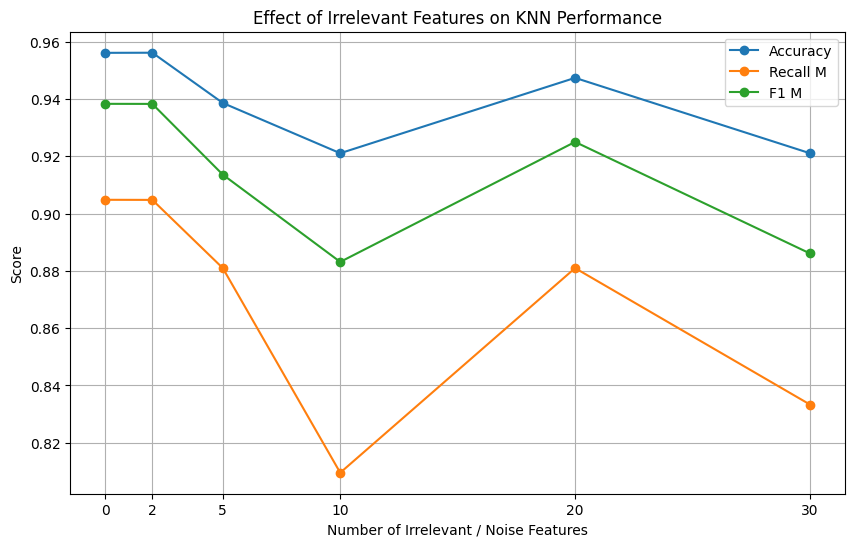

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    noise_results["Noise_Features"],
    noise_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    noise_results["Noise_Features"],
    noise_results["Recall_M"],
    marker="o",
    label="Recall M"
)

plt.plot(
    noise_results["Noise_Features"],
    noise_results["F1_M"],
    marker="o",
    label="F1 M"
)

plt.xlabel("Number of Irrelevant / Noise Features")
plt.ylabel("Score")

plt.title("Effect of Irrelevant Features on KNN Performance")

plt.xticks(noise_results["Noise_Features"])

plt.grid(True)
plt.legend()

plt.show()

**Observation**:

Adding irrelevant features generally reduced KNN performance compared with the original dataset. The baseline model with no noise achieved the highest accuracy, recall, and F1-score. However, performance did not decrease continuously as more noisy features were added; some configurations, such as 10 and 30 noisy features, showed partial recovery.




**Interpretation**:

This suggests that irrelevant dimensions can distort the distance calculations used by KNN and reduce classification quality. However, because the added features are random, their effect on neighborhood structure is also random. Some noise configurations may accidentally alter distances in ways that help a few test samples, so the degradation is not expected to be perfectly monotonic.
Conclusion: The experiment supports the idea that KNN is sensitive to irrelevant features, but the strength of the effect depends on the particular noise realization and dataset.

# Final Findings

The experiments in this project led to the following main findings:

- **Feature scaling significantly improved KNN performance.**
  Accuracy improved from approximately 91% to 96%, while malignant-class recall improved from about 0.79 to 0.90.

- **The value of K affects model behavior.**
  Among the tested values, `K = 5` and `K = 7` provided the strongest balance of accuracy, malignant recall, and F1-score.

- **Euclidean and Manhattan distance performed similarly in this setup.**
  Under the same preprocessing and `K = 5`, both distance metrics produced identical evaluation results.

- **The custom KNN implementation successfully reproduced scikit-learn's behavior.**
  The from-scratch implementation achieved the same 95.61% accuracy and 100% prediction agreement with scikit-learn on the test set.

- **Irrelevant features generally reduced KNN performance.**
  Adding random noise dimensions caused accuracy, malignant recall, and F1-score to generally decline compared with the original feature space.

- **The effect of irrelevant features was not strictly monotonic.**
  Because the added features were randomly generated, some noise configurations partially recovered performance. This shows that random features can alter neighborhood relationships in unpredictable ways.

# Limitations

Although the experiments provide useful insights into KNN behavior, this study has several limitations:

- **Single dataset:**  
  The experiments were conducted only on the Breast Cancer Wisconsin dataset. Therefore, the observed behavior may not generalize to datasets with different feature distributions, class structures, or dimensionalities.

- **Single train-test split:**  
  Most experiments used a fixed train-test split with `random_state=42`. Different splits may produce slightly different results.

- **Hyperparameter exploration on the test set:**  
  During the learning phase, multiple values of K were compared using the test set. A more rigorous approach would use cross-validation on the training data to choose K and reserve the test set only for final evaluation.

- **Limited distance metrics:**  
  Only Euclidean and Manhattan distance were compared. Other distance measures may behave differently.

- **Random noise experiment:**  
  The irrelevant-feature experiment used randomly generated features. Since the effect of random noise depends on the particular random values generated, repeating the experiment across several random seeds would provide a more reliable average estimate.

- **Limited model complexity:**  
  The custom implementation focuses on the basic KNN algorithm and does not include optimizations such as KD-trees, Ball Trees, weighted neighbors, or efficient nearest-neighbor search.

- **No external validation dataset:**  
  The final model was evaluated only on the held-out test portion of the same dataset rather than on a completely independent dataset.

# Conclusion

This project explored the K-Nearest Neighbors algorithm from both an implementation and an experimental perspective.

The study showed that preprocessing choices such as feature scaling can have a strong effect on KNN because the algorithm depends directly on distance calculations. Moderate values of K produced the best balance between sensitivity and generalization in this dataset, while Euclidean and Manhattan distance produced similar results under the tested setup.

A custom KNN classifier was also implemented from scratch using Python and NumPy. Its predictions matched the scikit-learn implementation with 100% agreement on the test set, which helped validate the correctness of the implementation.

The noisy-feature experiment further showed that irrelevant dimensions can reduce KNN performance by affecting neighborhood relationships, although the effect was not perfectly monotonic because the added features were randomly generated.

Overall, the project helped connect the mathematical idea behind KNN with practical implementation, controlled experimentation, model evaluation, and analysis of algorithm limitations.